# Regresión sobre dataset Flight Price Prediction

## Fase 1: EDA

### Acceso al dataset usando Kaggle-API

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


La siguiente celda hará prompt para ingresar usuario y API key de Kaggle.

In [2]:
import os, getpass
os.environ['KAGGLE_USERNAME'] = getpass.getpass('Enter your Kaggle username: ')
os.environ['KAGGLE_KEY'] = getpass.getpass('Enter your Kaggle API key: ')

Importación del dataset, por defecto usa colab + drive en ruta especificada.

In [3]:
from pathlib import Path
import kaggle
import pandas as pd

DATASET = "shubhambathwal/flight-price-prediction"   # slug en la URL de Kaggle
DATA_DIR = Path("/content/drive/MyDrive/Colab Notebooks/flight-price-prediction")  # ruta donde se guardará el dataset
DATA_DIR.mkdir(parents=True, exist_ok=True)

kaggle.api.dataset_download_files(DATASET, path=DATA_DIR, unzip=True)
print(sorted(p.name for p in DATA_DIR.iterdir()))


Dataset URL: https://www.kaggle.com/datasets/shubhambathwal/flight-price-prediction
['Clean_Dataset.csv', 'business.csv', 'economy.csv']


### Carga y exploración de datos

In [4]:
import pandas as pd
df = pd.read_csv(DATA_DIR / "Clean_Dataset.csv")
df.head()

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


#### Descripción del dataset:
El dataset proviene de un proceso de scraping realizado sobre una página de agendamiento de vuelos, y tiene en cuenta factores temporales y características del vuelo.

**Problema de negocio:** La variabilidad de los precios de los vuelos hace que comprar un vuelo sea impredecible, no hay acceso al algoritmo que actualiza los precios, por eso una observación del comportamiento de estos a lo largo del tiempo puede permitir optimizar el precio que se paga por un vuelo.

**Target:** Variable precio.

In [5]:
df.tail()

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
300148,300148,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,69265
300149,300149,Vistara,UK-826,Chennai,Afternoon,one,Night,Hyderabad,Business,10.42,49,77105
300150,300150,Vistara,UK-832,Chennai,Early_Morning,one,Night,Hyderabad,Business,13.83,49,79099
300151,300151,Vistara,UK-828,Chennai,Early_Morning,one,Evening,Hyderabad,Business,10.00,49,81585
300152,300152,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,81585


In [6]:
df.shape

(300153, 12)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  object 
 2   flight            300153 non-null  object 
 3   source_city       300153 non-null  object 
 4   departure_time    300153 non-null  object 
 5   stops             300153 non-null  object 
 6   arrival_time      300153 non-null  object 
 7   destination_city  300153 non-null  object 
 8   class             300153 non-null  object 
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 27.5+ MB


**Diccionario de características:** 
|Columna | Tipo esperado | Significado|
|-|-|-|
|Unnamed: 0|int|Índice de la fila.|
|airline|object (categórica)|Aerolínea que opera el vuelo.|
|flight|object (categórica)|Código del vuelo.|
|source_city|object (categórica)|Ciudad de origen.|
|departure_time|object (categórica ordinal)|Franja horaria de salida.|
|stops|object (categórica ordinal)|Número de escalas.|
|arrival_time|object (categórica ordinal)|Franja horaria de llegada.|
|destination_city|object (categórica)|Ciudad de destino.|
|class|object (categórica ordinal)|Clase del asiento (Economy/Business).|
|duration|float|Duración del vuelo en horas.|
|days_left|int|Días entre la compra y el vuelo.|
|price|int|Precio del tiquete (target).|

#### Limpieza

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.isnull().sum()

,0
Unnamed: 0,0
airline,0
flight,0
source_city,0
departure_time,0
stops,0
arrival_time,0
destination_city,0
class,0
duration,0


No hay valores faltantes ni columnas duplicadas, no es necesario interpolar o eliminar registros.

#### Análisis de características numéricas

In [10]:
df[["duration", "days_left", "price"]].describe()

,duration,days_left,price
count,300153.000000,300153.000000,300153.000000
mean,12.221021,26.004751,20889.660523
std,7.191997,13.561004,22697.767366
min,0.830000,1.000000,1105.000000
25%,6.830000,15.000000,4783.000000
50%,11.250000,26.000000,7425.000000
75%,16.170000,38.000000,42521.000000
max,49.830000,49.000000,123071.000000


**Observaciones:** 
- La distribución del precio está fuertemente sesgada a la derecha: la media (20890) >> mediana (7425). Y la desviación estándar (22698) es muy alta respecto a la mediana, lo que implica una alta variabilidad en los precios mayores al percentil 50 y un aumento desproporcional respecto al tamaño del dataset, esto es consistente con dos grupos de precios: Economy(más numeroso) y Business(más exlusivo y costoso).
- Los días restantes media tienen la media(26) igual que la mediana(26) lo que sugiere una distribución balanceada de los datos durante el tiempo de muestreo, esto indica que los datos son representativos del comportamiento de ventas de vuelos por el periodo observado sin ser afectados visiblemente por condiciones externas. Esta característica permite confiar en la correlación 1a1 entre días restantes y precio.
- Duración muestra vuelos desde 40 min hasta 2 días, se puede esperar una correlación fuerte entre las paradas de un vuelo y su duración, así como diferenciar el impacto en el precio de vuelos de la misma duración pero con o sin paradas. 

#### Boxplots y detección de outliers

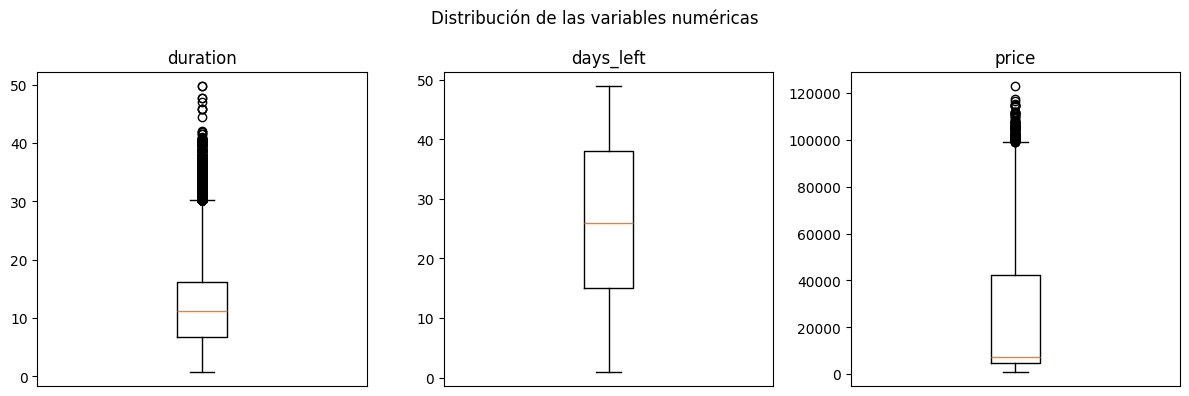

In [11]:
import matplotlib.pyplot as plt

num_cols = ["duration", "days_left", "price"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col in zip(axes, num_cols):
    ax.boxplot(df[col], vert=True, showfliers=True)
    ax.set_title(col)
    ax.set_xticks([])
fig.suptitle("Distribución de las variables numéricas")
fig.tight_layout()
plt.show()

In [12]:
reporte = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df[col] < low) | (df[col] > high)
    reporte.append({
        "columna": col,
        "iqr": iqr,
        "limite_inferior": low,
        "limite_superior": high,
        "n_outliers": int(mask.sum()),
        "%_outliers": round(100 * mask.mean(), 2)
    })

pd.DataFrame(reporte).set_index("columna")

,iqr,limite_inferior,limite_superior,n_outliers,%_outliers
columna,,,,,
duration,9.34,-7.18,30.18,2110,0.70
days_left,23.00,-19.50,72.50,0,0.00
price,37738.00,-51824.00,99128.00,123,0.04


**Outliers:** 
- duration: límite superior en 30.18 h. Los valores marcados son vuelos con varias escalas y conexiones muy largas, no errores de medición.
- price: tiene límite superior muy alto respecto a la media y al q2 99128, consistente con desbalance de precio entre economy y business, solo los precios más altos de business son anormales, por lo que sería conveniente tener en cuenta el precio observado según clase en vez de de forma homogénea.

#### Balance de clases

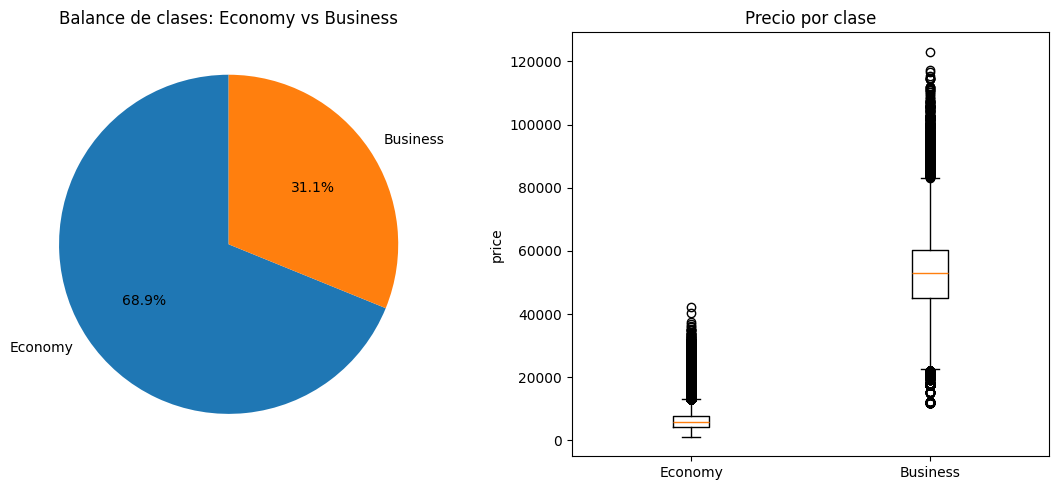

,count,min,max,mean,median,std
class,,,,,,
Business,93487,12000,123071,52540.08,53164.0,12969.31
Economy,206666,1105,42349,6572.34,5772.0,3743.52


In [13]:
conteo = df["class"].value_counts()
clases = list(conteo.index)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))

ax1.pie(conteo, labels=clases, autopct="%1.1f%%", startangle=90)
ax1.set_title("Balance de clases: Economy vs Business")

ax2.boxplot([df.loc[df["class"] == c, "price"] for c in clases], tick_labels=clases)
ax2.set_title("Precio por clase")
ax2.set_ylabel("price")

fig.tight_layout()
plt.show()

df.groupby("class")["price"].agg(["count", "min", "max", "mean", "median", "std"]).round(2)

In [19]:
economy = df[df["class"] == "Economy"]
q1, q3 = economy["price"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
high_outliers = economy[economy["price"] > high]
(high_outliers.shape[0]/df.shape[0]) * 100

4.58066386143067

Se puede observar una alta correlación entre la clase del ticket y su precio así como un desbalance de clase aproximadamente de 3 a 1, con los outliers de cada clase siendo los únicos que se solapan con el rango de precios de la otra, se puede suponer que esto es debido a la influencia de otras variables (como días restantes, duración, origen, destino, etc.) que, en un proceso de entrenamiento, podrían verse silenciadas por la fuerte correlación clase-precio, perdiendo información sobre escaladas de precio por tickets de última hora, etc. Sugiero en el diseño de un modelo predictivo considerar incluir en un diseño de ensamble final modelos donde se aísle por clase el dataset permitiendo extraer un posible sesgo producido por esta correlación y enriquecer el rendimiento en valores límite.

#### Relación entre días restantes y precio

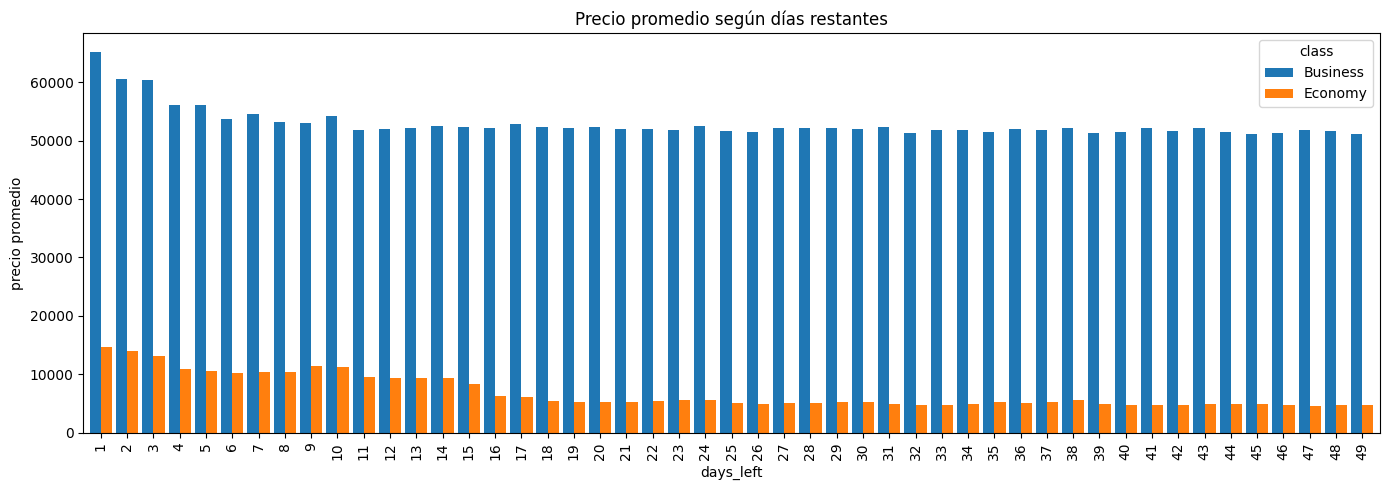

,days_left,price
days_left,1.000000,-0.091949
price,-0.091949,1.000000


In [14]:
precio_medio = df.groupby(["days_left", "class"])["price"].mean().unstack()

precio_medio.plot(kind="bar", figsize=(14, 5), width=0.85)
plt.xlabel("days_left")
plt.ylabel("precio promedio")
plt.title("Precio promedio según días restantes")
plt.legend(title="class")
plt.tight_layout()
plt.show()

df[["days_left", "price"]].corr()

**Interpretación:** La correlación lineal entre `days_left` y `price` es prácticamente nula (-0.09), pero el gráfico de barras muestra que sí existe una relación: el precio promedio se mantiene estable durante la mayor parte de la ventana de compra y se dispara en los últimos días antes del vuelo. Es decir, la anticipación no encarece el tiquete de forma proporcional —comprar con 40 o con 20 días de anticipación cuesta prácticamente lo mismo—, sino que el efecto se concentra en un tramo corto y no lineal al final, razón por la cual el coeficiente de Pearson lo subestima. A esto se suma que la magnitud del salto es muy distinta entre clases: sobre una base de 6.572 en Economy y 52.540 en Business, el mismo incremento porcentual representa montos absolutos incomparables. **Recomendación:** como responsable de la decisión, no invertiría en anticipar la compra más allá del punto en que el precio deja de bajar; la política de compra debería fijar una fecha límite (comprar antes de la ventana crítica de últimos días) en lugar de premiar la anticipación máxima, que no genera ahorro. Para el modelo, esto implica no tratar `days_left` como un efecto lineal: conviene transformarla o segmentarla en tramos (por ejemplo, última semana vs. resto) y modelar por clase, de modo que el modelo capture la escalada de última hora, que es justamente donde está el dinero en juego.